# Experimental Structural Modal Reconstruction


### Historical static audit (superseded by executed v2 validation)

<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `experimental_modal_identification` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：frequency (1, 9999) float64：Native measured frequency samples in Hz, ascending order.；accelerance (1, 6, 9999) complex128：Complex measured acceleration/force in m/(N s²); axes (batch, roving excitation, frequency).。恢复目标：七模态频率/阻尼、complex residues及上下残差和拟合FRF。

获取模型：共轭阻尼极点的频响叠加，加低频/高频残余项形成accelerance。实际恢复算法：solvers.identify_poles、stabilization、select_poles和fit_residues；reconstruct完整识别。语义类型为 `inverse_parameter`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:49为原始标准方法参数，没有独立真实模态参数。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：experimental_modal_identification.ipynb单元0：Experimental Structural Modal Reconstruction；experimental_modal_identification.ipynb单元4：5. Results；experimental_modal_identification.ipynb单元8：Scientific comparisons and recomputed experiments；experimental_modal_identification.ipynb单元10有保存图；图内容由该单元调用的本地visualization函数生成。图/比较代码位于单元5, 9, 10（从0计数）。代码单元4个，带execution_count的4个，保存PNG输出3幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Recover seven damped structural modes, complex spatial residues and residual terms from six measured accelerance responses with overlapping resonances and finite frequency coverage.

This maintainer notebook actively reconstructs the complete bound observations with local numerical modules. It distinguishes the independently reproduced original method from fresh cleaned results. There is no cache-preview path. The paper describes the selected model; the exact bound dataset and modern port have separate provenance.


## Current v2 physical decode and observable objective

The original pole selector reports a stabilization-table frequency/damping pair while using a neighboring chosen complex pole for residues and fitted FRFs. The independently checked discrepancy reaches0.147387Hz and0.000250615 damping; reconstructing FRFs from those reported values differs by1.8775% in one channel. V2 decodes natural frequency and damping from the actual chosen poles. Residues, lower/upper residuals and fitted FRFs are unchanged, and no frequency/noise tolerance is enlarged around that bug.

Current acceptance independently checks every measured in-band response and all derived fitted curves, permitting equal or better stable seven-mode fits. The archived v1 outputs below remain identified as historical diagnostics, not physical truth. All scientific order/response comparisons are retained and actively recomputed.

The lower-order diagnostic exposes a negative actual damping after correct decoding. It is retained and explicitly labeled as an unstable candidate, not an admissible benchmark reconstruction. The main seven-mode fit has positive damping throughout; the negative ablation is not silently removed or assigned a fabricated result.

## 2. Data

The input is `data/raw_data.npz`; all arrays include batch size one.

| Key | Shape | Dtype | Description |
| --- | --- | --- | --- |
| `frequency` | `(1, 9999)` | `float64` | Native measured frequency samples in Hz, ascending order. |
| `accelerance` | `(1, 6, 9999)` | `complex128` | Complex measured acceleration/force in m/(N s²); axes (batch, roving excitation, frequency). |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
| --- | --- | --- | --- |
| Input frequency convention | Cycles per second | Hz | Use omega=2πf |
| Analysis band | 10 to 5000 | Hz | Closest stored bins; upper cutoff is exclusive before fitting |
| Transfer quantity | Accelerance | m/(N s²) | Measured acceleration divided by force |
| Time convention | Laplace s=i omega | 1 | Stable poles have negative real part |
| Response reference | Index 1 in original seven-response author dataset | 1 | Entire six-excitation acquisition for that fixed response |
| Spatial axis | Roving excitation index 0..5 | 1 | No physical coordinate scale is supplied |
| Model size | Seven conjugate-paired flexible modes | 1 | All seven mode quantities are required |
| Fitted output grid | Prepend zero frequency, retain native bins before closest 5000 Hz bin | Hz | 4999 entries; zero-padding convention is explicit |
| Noise covariance | Not supplied | 1 | Unweighted frequency-domain model |


## 3. Physics

### Observation and inverse problem

For angular frequency omega=2πf, the complex accelerance at roving excitation index l is modeled as

$$
H_l(\omega)=-\omega^2\sum_{k=1}^{7}\left[\frac{A_{lk}}{\mathrm{i}\omega-p_k}+\frac{\overline{A_{lk}}}{\mathrm{i}\omega-\overline{p_k}}\right]+L_l-\omega^2U_l.
$$

Here f is frequency in Hz, p is a stable modal pole in s^-1, A is a complex residue in m/(N·s), the overbar is complex conjugation, L is the lower residual in m/(N·s²), and U is the upper residual in m/N. Natural frequency is abs(p)/(2π) Hz, and damping ratio is -Re(p)/abs(p). L and U represent contributions outside the fitted frequency band. Real physical impulse responses give conjugate pole pairs.

The bound observation consists of all 9999 frequency bins for each of six roving excitations at the fixed response index selected in the author showcase. Identify seven modes within the 10–5000 Hz analysis band and their complete six-location complex residues. Pole-residue factorization is sensitive to noise, polynomial order and out-of-band contributions; no measured spatial distances are supplied.


## 4. Method

### Implemented mathematics and numerical conventions

Use all native bins for the bound fixed-response experiment, but the selected method first truncates before the closest 5000 Hz sample. Set sampling interval dt=1/(2*f_last_retained) from the retained native grid before prepending missing bins from zero in steps df=f[1]-f[0]. The padded FRF columns are zeros. This preserves source conventions rather than pretending the input starts at DC. Analysis lower bin is closest 10 Hz. Maximum denominator degree is 120 (60 even polynomial orders).

For order limit n=120 and nf=2*(number_of_padded_bins-1), define adjusted inverse transforms F(x,q)=nf*irfft(x)[q]-nf*irfft(x[:lower])[q], keeping the two multiplications separate. Compute s=-F(H,q), q=-n..n; t=F(Re(H)²+Im(H)²,q), q=0..n; r=-nf*irfft(ones(lower))[0..n], then r[0]+=nf. Build Toeplitz S_l from the signed s sequence, T from sum_l(t_l), and R from r. At every even degree j, D_j=T_j-sum_l S_l,jᵀ R_j^-1 S_l,j. Solve -D[0:j,0:j]a=D[0:j,j], append last coefficient 1, reverse polynomial coefficient order for np.roots, and map roots z to p=-log(z)/dt. No nonlinear optimizer or arbitrary regularizer is used in this pole step.

Stabilization uses the source's signed frequency |p| sign(Im p)/(2π), damping -Re p/(|p| sign(Im p)), removes conjugate-frequency duplicates within 1e-3 Hz, and requires relative frequency change <0.001 and relative damping change <0.05 with positive damping. Preserve source order indexing, including its n=1 seed-order convention. Approximate observed resonance centers are [176,476,932,1534,2258,3161,4180] Hz. Recenter each using least_squares on stable frequencies in successively narrowed windows [25,16,12,10,8,7,6,5,5,4,4,4,3?] as actually generated by [50//i for i in range(2,100) if 50//i>3]+[2]; the executable comprehension is authoritative (no 3 Hz entry). Select the closest actual polynomial pole to the stabilized representative. These approximate centers are model initialization, not submitted answers or acquisition calibration.

For LSFD, evaluate the stated complex conjugate-residue formula separately for unit real and imaginary residue coefficients. Append real/imaginary columns for L and -omega² U. Stack real and imaginary observation equations and solve np.linalg.lstsq(rcond=None) over closest 10 Hz through the exclusive final retained bin. The returned natural frequency/damping are the stabilized representatives; residues use the selected actual polynomial poles, matching the source's subtle distinction. Coefficients and forward arrays retain their physical complex scale, without mode normalization. Notebook normalized real residues are explicitly display-only.

Root calculations on ill-conditioned high-order normal equations are sensitive to arithmetic grouping. Preserve Re(H)²+Im(H)² instead of abs(H)² and accumulate the negative S terms before adding T. Independent pole-residue analytic tests validate the signs and physical units. No structural geometry, displacement field or mass normalization is invented from the FRFs.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,time,json,subprocess,hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),Path.cwd().parent] if (p/'src').is_dir())
os.chdir(ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.main import run
from src.visualization import make_figures,relative_error
data=load_data()
display(Markdown('| Observation | Internal shape | Dtype |\n| --- | --- | --- |\n'+'\n'.join(f'| {k} | {v.shape} | {v.dtype} |' for k,v in data.items())))

| Observation | Internal shape | Dtype |
| --- | --- | --- |
| frequency | (9999,) | float64 |
| accelerance | (6, 9999) | complex128 |

### Fresh full reconstruction

The standard local path below computes every required output quantity from the bound public measurements and writes the declared submission. Runtime includes the complete reconstruction. Evaluation is a separate subprocess using the standalone Judge.


In [2]:
start=time.perf_counter()
fresh=run()
solver_runtime_s=time.perf_counter()-start
judge_process=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True,encoding='utf8',env=dict(os.environ,PYTHONIOENCODING='utf-8'))
assert judge_process.returncode==0,judge_process.stderr
judge_report=json.loads(Path('output/judge_report.json').read_text(encoding='utf8'))
assert judge_report['status']=='pass'
with np.load('notebooks/reference_outputs/reported_v1_outputs.npz',allow_pickle=False) as f:reference={k:f[k].copy() for k in f.files}
agreement={key:relative_error(fresh[key],reference[key]) for key in fresh}
print(json.dumps({'identity':'fresh cleaned full reconstruction','solver_runtime_s':solver_runtime_s,'historical_v1_decode_and_parameter_errors':agreement,'standalone_judge':judge_report},indent=2,allow_nan=False))

{
  "identity": "fresh cleaned full reconstruction",
  "solver_runtime_s": 0.1370119999628514,
  "historical_v1_decode_and_parameter_errors": {
    "natural_frequency": 2.7592079414471614e-05,
    "damping_ratio": 0.027885753854083494,
    "reconstruction": 0.0,
    "fitted_accelerance": 0.0,
    "lower_residual": 0.0,
    "upper_residual": 0.0
  },
  "standalone_judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "maximum_response_mse_excess": 0.0,
      "maximum_fitted_relative_l2": 1.1216114601381199e-13
    },
    "thresholds": {
      "maximum_response_mse_excess": {
        "comparison": "<=",
        "boundary": 1e-06
      },
      "maximum_fitted_relative_l2": {
        "comparison": "<=",
        "boundary": 1e-07
      }
    },
    "errors": []
  }
}


### Scientific comparisons and recomputed experiments

The reconstruction figure includes measured signal consistency and independently reproduced upstream comparison. The robustness figure recomputes its model/regularization and acquisition/calibration changes. Original arrays are comparison inputs only; every curve labeled fresh is computed here. Exact numerical trace arrays are returned for the separately archived figure exports.


In [3]:
experiment_start=time.perf_counter()
figures,plot_trace,experiment_metrics=make_figures(data,fresh,reference)
plt.close('all')
experiment_runtime_s=time.perf_counter()-experiment_start
measurement={'identity':'fresh cleaned notebook reconstruction and actively recomputed comparisons','raw_data_sha256':hashlib.sha256(Path('data/raw_data.npz').read_bytes()).hexdigest(),'solver_runtime_s':solver_runtime_s,'experiments_runtime_s':experiment_runtime_s,'historical_v1_decode_and_parameter_errors':agreement,'scientific_measurements':experiment_metrics,'judge':judge_report,'historical_paper_numbers_used':False}
Path('notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(measurement,indent=2,allow_nan=False)+'\n',encoding='utf8')
print(json.dumps(experiment_metrics,indent=2,allow_nan=False))

{
  "upstream_relative_error": 0.0,
  "observation_relative_error": 0.10063998896074228,
  "order_relative_response_error": [
    [
      30,
      0.057664209678194016
    ],
    [
      45,
      0.07572940092911881
    ],
    [
      60,
      0.10063998896074228
    ]
  ],
  "polynomial_order_unstable_modes": [
    1,
    0,
    0
  ],
  "natural_frequency_Hz": [
    177.0598487874965,
    477.36304088241286,
    933.1306262401907,
    1535.472963495878,
    2286.884132544065,
    3162.3755062855075,
    4181.938831634285
  ],
  "damping_ratio": [
    0.00770363952985558,
    0.0017030833312694398,
    0.0015901360866547275,
    0.001963803162781299,
    0.002811848887084394,
    0.002339957154623932,
    0.0014491064066678098
  ]
}


### Reconstruction

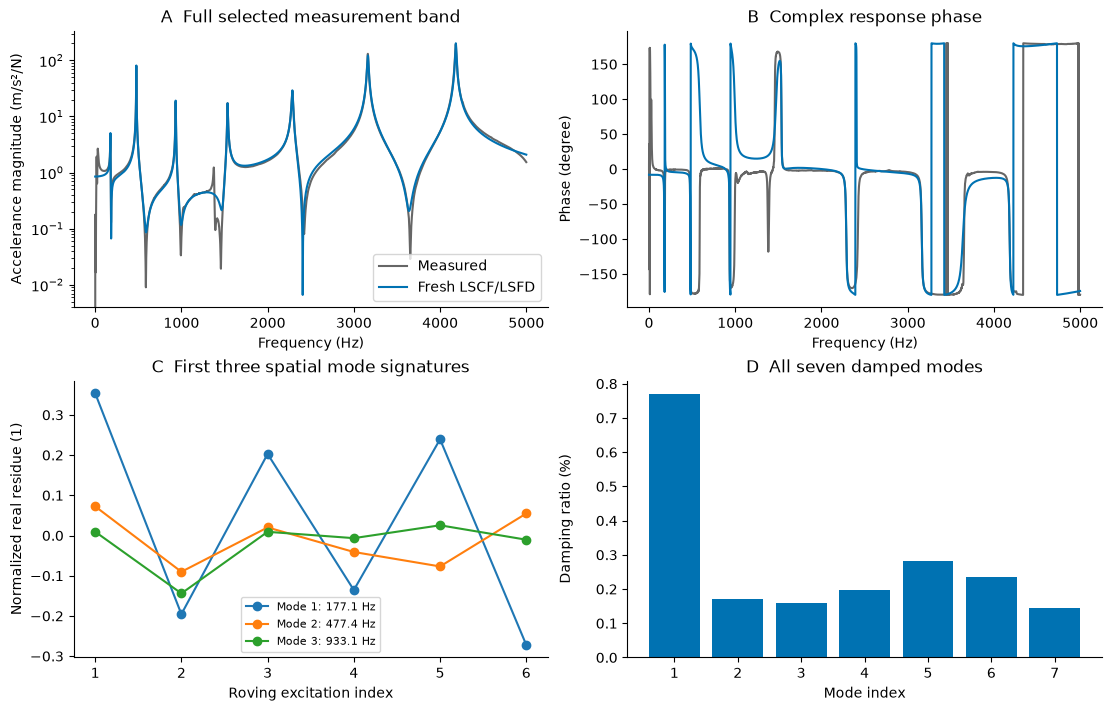

### Robustness

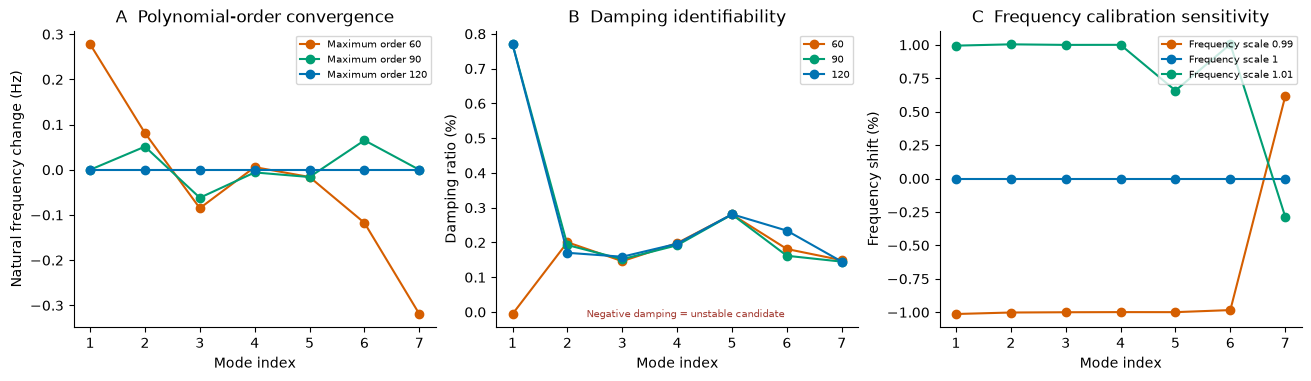

### Inverse Diagnostics

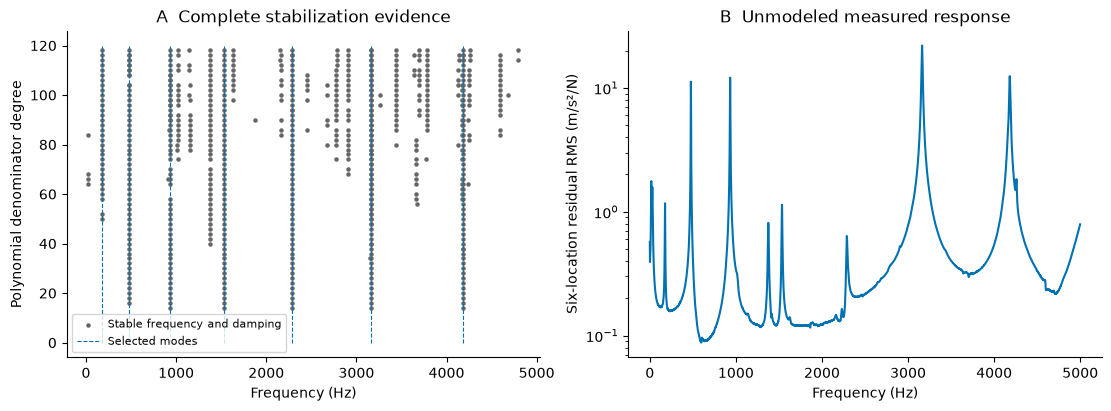

In [4]:
for figure_name,figure in figures.items():
    display(Markdown('### '+figure_name.replace('_',' ').title()))
    display(figure)
    plt.close(figure)

### Sources

Peeters et al., The PolyMAX frequency-domain method: a new standard for modal parameter estimation?, Shock and Vibration 11 (2004), 395–409. https://doi.org/10.1155/2004/523692

Data and executable method source are the author-maintained experimental/operational modal-analysis package and its measured accelerance showcase; this is a modern numerical port, not the original commercial software implementation.


## 6. Conclusion

### Interpretation and limitations

All seven selected modes and all six spatial residue vectors are retained, along with both complex residual terms. Frequency estimates are stable across polynomial orders, while damping of the first mode changes substantially and the response residual is not monotonic in maximum order. The baseline is a reproducible selected seven-mode approximation, not an exact model of every measured spectral feature. Calibration perturbations can change the selected stable pole for high modes; the figure exposes this discontinuity. Spatial curves use roving index, not invented coordinates or mass-normalized mode shapes.

Agreement with the standard method establishes implementation fidelity. Independent mathematical tests check operators and signs, while measured residuals and sensitivity studies bound physical interpretation. No reconstruction is relabeled as ground truth.

The seven selected modes are an approximation to six measured accelerance responses, with lower/upper residual terms for omitted frequency content. Stabilization and polynomial-order sweeps test estimator sensitivity; roving index is not a measured distance or a mass-normalized structural mode.


**V2 interpretation:** The complete run above now decodes physical frequency/damping from the actual chosen poles. Historical v1 frequency/damping mismatch is retained and identified, while source polynomial roots/residues/FRFs remain unchanged. Current acceptance uses full observable FRF quality and representation consistency, not old parameter identity. No measured modal truth or frequency/phase alignment is introduced.